<div class="langswitch">
  <a href="#lang-en">English</a> · <strong>فارسی</strong>
</div>

# K-medoids

![](img/banner.png)

گروه علوم کامپیوتر، دانشگاه فردوسی مشهد


## جای این صفحه در درس

بند ۱۴.۳.۱۰ از {cite}`hastie2009esl` (صص ۵۱۵–۵۱۸) دو محدودیتی را که K-means از تابع هدفش می‌گیرد جبران می‌کند: به **مقدار ویژگی** برای میانگین‌گیری نیاز دارد، و فاصلهٔ اقلیدسی مجذور به فاصله‌های بزرگ بیشترین تأثیر را می‌دهد و همین آن را **در برابر داده‌های پرت شکننده** می‌کند.

جبران کار کوچکی است. از دو گام K-means تنها یکی از فاصلهٔ مجذور بهره می‌برد: جانشین‌کردن هر خوشه با میانگینش. اگر آن گام با «جانشین‌کردن هر خوشه با یکی از مشاهده‌های خودش» عوض شود، هر نامتشابهی‌ای به کار می‌آید — از جمله ماتریس‌های نزدیکی [صفحهٔ پیش](Proximity-Matrices-and-Dissimilarity.ipynb) که در آن‌ها میانگین‌گیری ممکن نیست.

### در پایان باید بتوانید

* الگوریتم ۱۴.۲ را بنویسید و به تنها خطی اشاره کنید که با K-means تفاوت دارد؛
* بگویید چرا K-medoids ماتریس نامتشابهی دلبخواه می‌پذیرد و K-means نه؛
* هزینه را بشمارید: $O(N_k^2)$ به‌جای $O(N_k)$ در هر خوشه، و بگویید این هزینه کجا می‌ارزد؛
* مثال نامتشابهی کشورها را بخوانید، با ماتریس بازچینی‌شده و نمایش MDS آن.


## ۱. تنها گامی که فاصلهٔ مجذور را فرض می‌کند

K-means پراکندگی درون‌خوشه‌ای را کمینه می‌کند و این کار را با تناوب دو گام انجام می‌دهد: هر نقطه را به نزدیک‌ترین مرکز نسبت بده، سپس هر مرکز را به میانگین نقطه‌هایش ببر. گام دوم *تنها* برای فاصلهٔ اقلیدسی مجذور بهینه است، چون (۱۴.۳۲) کتاب می‌گوید

$$
\bar{x}_S = \arg\min_{m} \sum_{i \in S} \lVert x_i - m \rVert^2 ,
$$

که همان میانگین است و نه چیز دیگر. فاصله را عوض کنید و میانگین دیگر بهترین نماینده نیست؛ فاصله را با جدولی از نامتشابهی‌ها جانشین کنید و میانگین حتی تعریف‌شده نیست.

بیان کلی روش، معیار را نگه می‌دارد و میان‌بُر را دور می‌ریزد. مرکز $m_k$ از خوشهٔ $C_k$ چنان برگزیده می‌شود که مجموع نامتشابهی تا اعضای خود خوشه کمینه شود:

$$
m_k = \arg\min_{m \in C_k} \sum_{i \in C_k} D(x_i, m).
$$

برای $D$ عمومی، این کمینه‌سازی جست‌وجویی است روی مشاهده‌های خود خوشه، و کمینه‌ساز یک مشاهده است — یک **مدوئید**. نقطهٔ تازه‌ای نیست، مرکزی‌ترین نقطهٔ *موجود* است؛ از همین رو می‌توان مدوئید را به خبرهٔ حوزه نشان داد و از همین رو برای دادهٔ اسمی هم وجود دارد.


## ۲. الگوریتم ۱۴.۲

همان‌گونه که در {cite}`hastie2009esl`، ص ۵۱۶ آمده است:

1. برای افراز داده‌شدهٔ $C$، در هر خوشه مشاهده‌ای را بیابید که مجموع فاصله تا بقیهٔ نقطه‌های آن خوشه کمینه شود:
   $$
   i_k = \arg\min_{\{i: C(i)=k\}} \sum_{C(i')=k} D(x_i, x_{i'}),
   \qquad \text{(14.35)}
   $$
   و $m_k = x_{i_k}$ بگذارید برای $k = 1,\dots,K$.
2. با مرکزهای داده‌شده، هر مشاهده را به نزدیک‌ترین مرکز نسبت دهید:
   $$
   C(i) = \arg\min_{1 \le k \le K} D(x_i, m_k).
   \qquad \text{(14.36)}
   $$
3. تکرار کنید تا انتساب‌ها دیگر تغییر نکنند.

بهای کار در شمار خط‌های دو گام دیده می‌شود. گام ۲ هزینه‌ای $K \cdot N$ دارد، مانند K-means. گام ۱ در هر خوشه $N_k^2$ هزینه دارد نه $N_k$، چون هر عضو با هر عضو دیگر مقایسه می‌شود؛ در یک اجرای کامل این تفاوت میان کار خطی و درجه‌دوم در هر خوشه است. کتاب صریح می‌گوید: K-medoids از K-means بسیار سنگین‌تر است.

با این حال الگوریتم ۱۴.۲ یک روش ابتکاری برای مسئلهٔ ترکیبیاتی $\min_{C,\{i_k\}} \sum_k \sum_{C(i)=k} D(x_i, x_{i_k})$ (۱۴.۳۸) است. **PAM** کافمن و روسو با کوشش برای *مبادلهٔ* یک مدوئید کنونی با یک نامدوئید و نگه داشتن مبادله‌ای که معیار را بیشتر کم می‌کند آن را بهبود می‌دهد، تکرار تا وقتی هیچ مبادله‌ای سود ندهد؛ ماسارت و همکاران روش شاخه‌وباندی می‌دهند که برای مجموعه‌داده‌های بسیار کوچک بهینهٔ جهانی را می‌یابد.

زیر همان الگوریتم ۱۴.۲ نوشته‌شده است، با شروع‌های تصادفی متعدد چون — مانند [صفحهٔ خانواده‌ها](Three-Families-of-Clustering-Algorithms.ipynb) — معیار کمینهٔ محلی دارد.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

names = ["BEL", "BRA", "CHI", "CUB", "EGY", "FRA",
         "IND", "ISR", "USA", "USS", "YUG", "ZAI"]
lower = {
    "BRA": [5.58],
    "CHI": [7.00, 6.50],
    "CUB": [7.08, 7.00, 3.83],
    "EGY": [4.83, 5.08, 8.17, 5.83],
    "FRA": [2.17, 5.75, 6.67, 6.92, 4.92],
    "IND": [6.42, 5.00, 5.58, 6.00, 4.67, 6.42],
    "ISR": [3.42, 5.50, 6.42, 6.42, 5.00, 3.92, 6.17],
    "USA": [2.50, 4.92, 6.25, 7.33, 4.50, 2.25, 6.33, 2.75],
    "USS": [6.08, 6.67, 4.25, 2.67, 6.00, 6.17, 6.17, 6.92, 6.17],
    "YUG": [5.25, 6.83, 4.50, 3.75, 5.75, 5.42, 6.08, 5.83, 6.67, 3.67],
    "ZAI": [4.75, 3.00, 6.08, 6.67, 5.00, 5.58, 4.83, 6.17, 5.67, 6.50, 6.92],
}

n = len(names)
D = np.zeros((n, n))
for i, country in enumerate(names[1:], start=1):
    for j, value in enumerate(lower[country]):
        D[i, j] = D[j, i] = value


def k_medoids(D, K, n_starts=60, seed=0, max_iter=100):
    """Algorithm 14.2 with random starts; keeps the best solution found."""
    rng = np.random.default_rng(seed)
    N = len(D)
    best = None
    for _ in range(n_starts):
        med = rng.choice(N, K, replace=False)
        for _ in range(max_iter):
            lab = D[:, med].argmin(axis=1)
            new = med.copy()
            for k in range(K):
                members = np.where(lab == k)[0]
                if len(members) == 0:
                    continue
                sub = D[np.ix_(members, members)]
                new[k] = members[sub.sum(axis=1).argmin()]
            new = np.sort(new)
            if np.array_equal(new, med):
                break
            med = new
        lab = D[:, med].argmin(axis=1)
        if len(np.unique(med)) < K:            # two clusters chose the same medoid
            continue
        cost = D[np.arange(N), med[lab]].sum()
        if best is None or cost < best[0]:
            best = (cost, med.copy(), lab.copy())
    return best


cost, medoids, labels = k_medoids(D, K=3)
print("criterion (sum of distances to the medoid):", round(cost, 2))
print("medoids:", [names[i] for i in medoids])
for k in range(3):
    members = [names[i] for i in np.where(labels == k)[0]]
    print(f"  cluster {k}: {members}")

criterion (sum of distances to the medoid): 30.08
medoids: ['CUB', 'USA', 'ZAI']
  cluster 0: ['CHI', 'CUB', 'USS', 'YUG']
  cluster 1: ['BEL', 'EGY', 'FRA', 'ISR', 'USA']
  cluster 2: ['BRA', 'IND', 'ZAI']


سه گروه بیرون می‌آید و همان‌هایی است که خوانندهٔ پیمایش ۱۹۹۰ انتظار دارد: گروهی غربی گرد ایالات متحده، فرانسه، اسرائیل و بلژیک؛ گروهی دوم گرد کوبا و اتحاد جماهیر شوروی همراه چین و یوگسلاوی؛ و گروهی سوم از برزیل، هند و زئیر. مصر به گروه غربی می‌پیوندد، ولی نمایش MDS زیر نشان می‌دهد چرا کتاب آن را جدا می‌کند: تقریباً وسط دو گروه می‌نشیند، پس انتسابش چند دهمِ یک واحد نامتشابهی است.

پنل چپ شکل ۱۴.۱۰ کتاب ماتریس نامتشابهی است با سطرها و ستون‌هایی که بر پایهٔ خوشه بازچینی شده‌اند تا بلوک‌ها روی قطر بیایند.


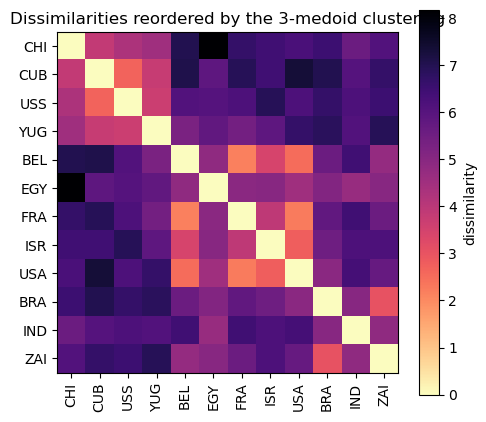

In [2]:
order = np.argsort(labels, kind="stable")
fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(D[np.ix_(order, order)], cmap="magma_r")
ax.set_xticks(range(n))
ax.set_xticklabels([names[i] for i in order], rotation=90)
ax.set_yticks(range(n))
ax.set_yticklabels([names[i] for i in order])
ax.set_title("Dissimilarities reordered by the 3-medoid clustering")
fig.colorbar(im, ax=ax, label="dissimilarity")
plt.show()

سه بلوک تیره روی قطر همان سه خوشه‌اند: درون یک بلوک درایه‌ها کوچک‌اند، میان بلوک‌ها بزرگ. این تصویر خودِ خوشه‌بندی است و از فهرستی از برچسب‌ها ارزش بیشتری دارد، چون درایه‌های بیرون قطر نشان می‌دهند گروه‌ها *چقدر* به هم نزدیک‌اند — بلوک برزیل از هر دو بلوک دیگر دور است، بلوک‌های غربی و شوروی سابق آن‌قدرها دور نیستند.


## ۳. همان خوشه‌بندی در دو بُعد

فاصله‌ها را نمی‌توان کشید، ولی **مقیاس‌بندی چندبُعدی** دوبُعدی آن‌ها را می‌توان: نقطه‌هایی بیابید که فاصله‌های اقلیدسی جفتی‌شان تا حد ممکن به نامتشابهی‌های داده‌شده نزدیک باشد. پنل راست شکل ۱۴.۱۰ همین نمودار است؛ ابزاری تشخیصی است نه اثبات، چون دو مختصه برازش می‌شوند و می‌توان آن‌ها را دلبخواه چرخاند یا بازتاب داد.


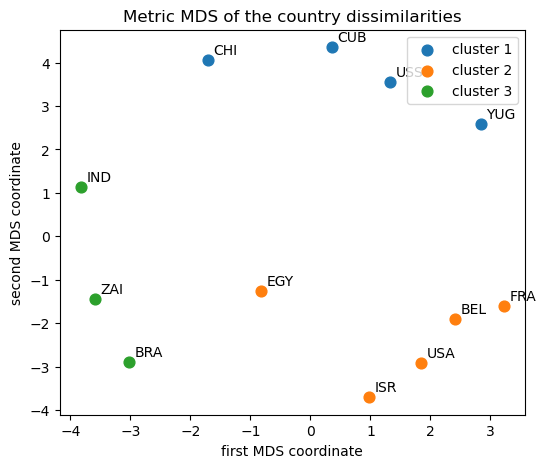

In [3]:
from sklearn.manifold import MDS

mds = MDS(n_components=2, dissimilarity="precomputed", random_state=0, n_init=10)
Y = mds.fit_transform(D)

colours = ["tab:blue", "tab:orange", "tab:green"]
fig, ax = plt.subplots(figsize=(6, 5))
for k in range(3):
    ax.scatter(Y[labels == k, 0], Y[labels == k, 1],
               s=60, color=colours[k], label=f"cluster {k + 1}")
for i, name in enumerate(names):
    ax.annotate(name, (Y[i, 0], Y[i, 1]), xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("first MDS coordinate")
ax.set_ylabel("second MDS coordinate")
ax.legend()
ax.set_title("Metric MDS of the country dissimilarities")
plt.show()

## ۴. چرا روی دادهٔ ویژگی‌دار همان K-means را به کار نبریم؟

با دادهٔ ویژگی‌دار هر دو روش کار می‌کنند، پس انتخاب دربارهٔ تابع زیان است. فاصلهٔ اقلیدسی مجذور یک تفاوت بزرگ را در خودش ضرب می‌کند، پس چند نقطهٔ دور می‌توانند میانگین را از تودهٔ خوشه دور کنند؛ ولی مجموع فاصله‌ها، که مدوئید آن را کمینه می‌کند، یک انحراف بزرگ را خطی می‌بیند. آزمایش زیر کوچک‌ترین شکل این اثر است: یک ابر جمع‌وجور ۴۰ نقطه‌ای و سه نقطهٔ دور. میانگین آن ۴۳ نقطه به سوی نقطه‌های پرت کشیده می‌شود؛ مدوئید یکی از مشاهده‌هاست و نمی‌تواند جابه‌جا شود.


In [4]:
rng = np.random.default_rng(5)
cloud = rng.normal((0.0, 0.0), 0.6, size=(40, 2))
stragglers = np.array([[6.0, 5.0], [7.0, 6.0], [5.5, 7.0]])
P = np.vstack([cloud, stragglers])

P_dist = np.sqrt(((P[:, None, :] - P[None, :, :]) ** 2).sum(-1))
mean_of_P = P.mean(axis=0)
medoid_of_P = P[P_dist.sum(axis=1).argmin()]

print("true centre of the cloud     : (0.00, 0.00)")
print("mean of all 43 points        :", np.round(mean_of_P, 2))
print("medoid of all 43 points      :", medoid_of_P)
print(f"distance from the true centre: mean {np.linalg.norm(mean_of_P):.2f}, "
      f"medoid {np.linalg.norm(medoid_of_P):.2f}")

true centre of the cloud     : (0.00, 0.00)
mean of all 43 points        : [0.42 0.24]
medoid of all 43 points      : [-0.02273144 -0.18260265]
distance from the true centre: mean 0.48, medoid 0.18


فاصلهٔ سطر آخر تمام استدلال است. مرکز یک موقعیت محاسبه‌شده است: می‌تواند میان دو گروه بیفتد، یا کلاً بیرون از داده، وقتی خوشه نقطه‌ای را در خود دارد که به آن تعلق ندارد. مدوئید همیشه یکی از مشاهده‌هاست، پس بدترین حالتش «عضوی واقعی از خوشه که چندان مرکزی نیست» است، هرگز «جایی که هیچ اندازه‌گیری‌ای در آن انجام نشده». روی دادهٔ تمیز ویژگی‌دار دو روش معمولاً هم‌نظرند، پس دلیل ترجیح K-medoids دقت نیست — بلکه این است که جوابش در برابر همان نوع نقطه‌ای که در دادهٔ واقعی فراوان است (اندازه‌گیری بدثبت‌شده، دُم سنگین، پاسخ‌دهندهٔ بی‌دقتی در پیمایش) استوار می‌ماند.

هزینه واقعی است، پس قاعدهٔ عملی چنین است:

* **دادهٔ ویژگی‌دار، زیان مجذور پذیرفتنی، نقطه‌های زیاد** — K-means؛
* **تنها نامتشابهی‌ها در دست** (پیمایش کشورها، ماتریس درهم‌ریختگی، جدول ویرایش رشته) — K-medoids، که تنها گزینه است؛
* **دادهٔ ویژگی‌دار با داده‌های پرت، یا $K$ کوچک و $N$ متوسط** — K-medoids اگر گام درجه‌دوم قابل‌تحمل باشد، وگرنه K-means روی میانه‌ها یا گونه‌ای بریده.


## خلاصه

* K-medoids همان K-means است با میانگینی که با عضوی از خوشه جانشین شده؛ این هم فرض فاصلهٔ مجذور و هم نیاز به مختصات را برمی‌دارد.
* الگوریتم ۱۴.۲ (۱۴.۳۵) و (۱۴.۳۶) را متناوب می‌کند؛ تنها گام ۱ تازه است و $O(N_k^2)$ در هر خوشه هزینه دارد.
* معیار (۱۴.۳۸) هم کمینهٔ محلی دارد، پس شروع‌های متعدد هنوز لازم‌اند؛ PAM مدوئیدها را مبادله می‌کند و شاخه‌وباند نمونه‌های بسیار کوچک را دقیق حل می‌کند.
* روی دادهٔ کشورها سه مدوئید سه گروه قابل‌تفسیر می‌دهند، و ماتریس بازچینی‌شده و نمودار MDS دو راهی‌اند که کتاب برای نمایش‌شان به کار می‌برد.
* دلیل به‌کارگیری‌اش استواری و عمومیت است، نه دقت روی دادهٔ تمیز ویژگی‌دار.


## تمرین‌ها

1. در `k_medoids` گام به‌روزرسانی مدوئید را با به‌روزرسانی میانگین جانشین کنید و آن را روی ماتریس کشورها اجرا کنید. چه چیزی می‌شکند، و چرا همان تمام هدف این بند است؟
2. مبادلهٔ کافمن–روسو را پیاده کنید: از جواب الگوریتم ۱۴.۲، هر مدوئید را با هر نامدوئید مبادله کنید و بهترین مبادله را نگه دارید. معیار روی دادهٔ کشورها چقدر بهتر می‌شود؟
3. کشورها را با $K = 2$ و $K = 4$ خوشه‌بندی کنید. کدام گروه اول می‌شکند، و مصر جابه‌جا می‌شود؟
4. مدوئیدهای $K = 3$ را با خوشه‌بندی‌ای که از نامتشابهی‌های مجذور $D^2$ می‌گیرید مقایسه کنید. کدام خوشه‌ها عوض می‌شوند؟
5. هر دو روش را روی دادهٔ زنبق برای $N = 150$ و برای نمونه‌ای با $N = 1500$ زمان‌سنجی کنید. نسبت زمان‌ها با $N$ چگونه رشد می‌کند؟
6. K-medoids با *میانه* هر مختصه به‌جای مدوئید، گونهٔ استوار دیگری است. آیا همان الگوریتم است؟ اگر نه، مثال نقض بدهید.


## منابع

* الگوریتم ۱۴.۲، (۱۴.۳۵)–(۱۴.۳۸)، نکتهٔ پیچیدگی و مثال کشورها: بند ۱۴.۳.۱۰ از {cite}`hastie2009esl`، صص ۵۱۵–۵۱۸.
* دادهٔ پیمایش (جدول ۱۴.۳) و PAM: Kaufman and Rousseeuw (1990)، همان‌جا ارجاع داده شده؛ همان ماتریس در [صفحهٔ ماتریس‌های نزدیکی](Proximity-Matrices-and-Dissimilarity.ipynb) به کار رفته است.
* مقیاس‌بندی چندبُعدی بند ۱۴.۸ همان کتاب است؛ `sklearn.manifold.MDS` نسخهٔ متری را که بالا به کار رفت پیاده می‌کند.
